# Évaluation à l'échelle globale

In [ ]:
import logging
import os
import sys

import numpy as np

_path = '../..'
if _path not in sys.path:
    sys.path.append(_path)

from src.mod_plot import *
from src.mod_stat import *
from src.mod_spectral import *
from src.mod_interp import *

logger = logging.getLogger()
logger.setLevel(logging.INFO)


## Paramètres

À modifier et à adapter pour chaque _mapping_ à évaluer :

In [ ]:
method_name = 'miost'
method_path = (
    '/Odyssey/public/data_challenge_2024/REPROCESSING_L3_KARIN_V3.0/mapping/mapping_-180.0_180.0_-90.0_90.0_20231215_20250115_alg_j3n_s3a_s3b_s6a-lr_component_geos_lwe.nc'
)

# Méthode d'interpolation à utiliser pour le regrillage du mapping ;
# grille à utiliser pour la réinterpolation (chemin vers un fichier
# netCDF4 avec les mêmes noms de dimensions que le mapping)
interpolation_method = None

# Appliquer le masque des terres si le mapping à évaluer n'en contient
# pas déjà
apply_mask = False

Paramètres génériques, pas trop besoin de modifier (normalement) :

In [3]:
time_min = '2023-12-31'
time_max = '2025-01-01'
output_dir = './results'

# Échelles spatiales (en km) pour le filtrage du signal
lambda_min = 65.
lambda_max = 500.

# Longueur le long de la trace (en km) à considérer pour l'analyse
# spectrale
segment_length = 1000.

lat_max = 80
lat_min = -80

# output statistical and spectral analysis filename
stat_output_filename = f'{output_dir}/stat_sla_{method_name}.nc'
psd_output_filename = f'{output_dir}/psd_sla_{method_name}.nc'

In [4]:
os.system(f'mkdir -p {output_dir}')
os.system(f'rm -f {stat_output_filename}')
os.system(f'rm -f {psd_output_filename}')

0

## Données

### Référence (Saral/AltiKa)

In [5]:
ds_alg = xr.open_dataset('alg_2024.nc')
ds_alg[['sla_unfiltered', 'lwe']]

<xarray.Dataset> Size: 601MB
Dimensions:         (time: 15023042)
Coordinates:
  * time            (time) datetime64[ns] 120MB 2024-01-01T00:14:49.803840 .....
    latitude        (time) float64 120MB ...
    longitude       (time) float64 120MB ...
Data variables:
    sla_unfiltered  (time) float64 120MB ...
    lwe             (time) float64 120MB ...
Attributes: (12/44)
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Swath
    comment:                         Sea surface height measured by altimeter...
    contact:                         servicedesk.cmems@mercator-ocean.eu
    creator_email:                   servicedesk.cmems@mercator-ocean.eu
    ...                              ...
    summary:                         SSALTO/DUACS Delayed-Time Level-3 sea su...
    time_coverage_duration:          P23H0M10.645181S
    time_coverage_end:               2024-01-01T23:15:00Z
    time_coverage_resolution:        P1S
    time_coverage_start:             2024-01-01T00:14:49Z
    title:                           DT Altika Drifting Phase Global Ocean Al...

### _Mapping_ à évaluer

In [6]:
if method_path.endswith('.nc'):
    ds_maps = (
        xr.open_dataset(method_path)
        .sel(time=slice(time_min, time_max))
        [['sla']]
    )

    resolution = (ds_maps.longitude[1] - ds_maps.longitude[0]).item()
    ds_maps = (
        ds_maps
        .pad(
            pad_width=dict(longitude=1),
            mode='wrap',
        )
        .assign(longitude=np.concatenate((
            [ds_maps.longitude[0].item() - resolution,],
            ds_maps.longitude.values,
            [ds_maps.longitude[-1].item() + resolution,],
        )))
    )

    ds_maps.longitude.attrs['units'] = 'degrees_east'
    ds_maps.latitude.attrs['units'] = 'degress_north'
else:  # DUACS, MIOST & NeurOST sont divisés en plusieurs fichiers
    ds_maps = (
        xr.open_mfdataset(
            f'{method_path}/*.nc',
            combine='nested',
            concat_dim='time',
        )
        .sel(time=slice(time_min, time_max))
        [['sla']]
    )

ds_maps

<xarray.Dataset> Size: 12GB
Dimensions:    (time: 366, latitude: 1441, longitude: 2880)
Coordinates:
  * longitude  (longitude) float64 23kB -180.0 -179.9 -179.8 ... 179.8 179.9
  * latitude   (latitude) float32 6kB -90.0 -89.88 -89.75 ... 89.75 89.88 90.0
  * time       (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
Data variables:
    sla        (time, latitude, longitude) float64 12GB dask.array<chunksize=(1, 1441, 2880), meta=np.ndarray>
Attributes: (12/45)
    description:                      Miost analysis 
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Grid
    comment:                         Sea Surface Height measured by Altimetry...
    contact:                         
    ...                              ...
    summary:                         Experimental SSALTO/DUACS Delayed-Time L...
    time_coverage_duration:          P1D
    time_coverage_resolution:        P1D
    title:                           DT merged all satellites Global Ocean Gr...
    time_coverage_start:             2024-01-01T12:00:00Z
    time_coverage_end:               2024-01-01T12:00:00Z

Réinterpolation du _mapping_ :

In [7]:
if interpolation_method:
    ds_maps = (
        ds_maps
        .interp(
            coords=dict(
                latitude=np.arange(ds_maps.latitude[0], ds_maps.latitude[-1], 1/12),
                longitude=np.arange(ds_maps.longitude[0], ds_maps.longitude[-1] , 1/12),
            ),
            method=interpolation_method,
        )
    )
    ds_maps

In [8]:
if (lat_max is not None) or (lat_min is not None):
    ds_maps = ds_maps.sel(latitude=slice(lat_min, lat_max))

In [9]:
ds_maps.longitude.attrs['units'] = 'degrees_east'
ds_maps.latitude.attrs['units'] = 'degrees_north'

## Interpolation du _mapping_ le long de la trace Saral/Altika

In [ ]:
ds_interp = run_interpolation(ds_maps, ds_alg)
ds_interp = ds_interp.dropna('time')
ds_interp


2026-06-25 01:15:33 INFO     fetch data from 2024-01-01 00:00:00 to 2024-02-01 00:00:00
2026-06-25 01:15:37 INFO     fetch data from 2024-01-31 00:00:00 to 2024-03-01 00:00:00
2026-06-25 01:15:41 INFO     fetch data from 2024-02-29 00:00:00 to 2024-04-01 00:00:00
2026-06-25 01:15:45 INFO     fetch data from 2024-03-31 00:00:00 to 2024-05-01 00:00:00
2026-06-25 01:15:50 INFO     fetch data from 2024-04-30 00:00:00 to 2024-06-01 00:00:00
2026-06-25 01:15:53 INFO     fetch data from 2024-05-31 00:00:00 to 2024-07-01 00:00:00
2026-06-25 01:15:57 INFO     fetch data from 2024-06-30 00:00:00 to 2024-08-01 00:00:00
2026-06-25 01:16:01 INFO     fetch data from 2024-07-31 00:00:00 to 2024-09-01 00:00:00
2026-06-25 01:16:04 INFO     fetch data from 2024-08-31 00:00:00 to 2024-10-01 00:00:00
2026-06-25 01:16:08 INFO     fetch data from 2024-09-30 00:00:00 to 2024-11-01 00:00:00
2026-06-25 01:16:12 INFO     fetch data from 2024-10-31 00:00:00 to 2024-12-01 00:00:00
2026-06-25 01:16:15 INFO     fet

<xarray.Dataset> Size: 714MB
Dimensions:            (time: 14867442)
Coordinates:
  * time               (time) datetime64[ns] 119MB 2024-01-01T00:14:49.803840...
Data variables:
    sla_unfiltered     (time) float64 119MB -0.019 0.012 0.011 ... 0.024 0.039
    lwe                (time) float64 119MB -0.011 -0.011 -0.011 ... 0.0 0.0
    latitude           (time) float64 119MB -3.058 -2.996 -2.628 ... 77.74 77.78
    longitude          (time) float64 119MB 85.06 85.04 84.96 ... 46.87 46.66
    msla_interpolated  (time) float64 119MB -0.02183 -0.02003 ... 0.03742

Nombre de points attendus : 14 138 044

In [11]:
print(f">>> Nombre de points interpolés : {ds_interp.time.size}")

>>> Nombre de points interpolés : 14867442


In [22]:
ds_interp[['sla_unfiltered', 'lwe', 'latitude', 'longitude', 'sla_filtered']].to_netcdf('alg_2024_miost_mask.nc')

## Calcul de métriques

### Métriques statistiques

In [12]:
compute_stat_scores(
    ds_interp, lambda_min, lambda_max, stat_output_filename,method_name,
)

2026-06-25 01:17:28 INFO     Compute mapping error all scales
2026-06-25 01:17:28 INFO     Compute mapping error for scales between 65.0 and 500.0 km


Total RMSE= 0.038302114442524515 m
Total RMSE score= 0.7352223453764759 m


2026-06-25 01:18:23 INFO     Compute binning statistics
2026-06-25 01:18:34 INFO     Compute statistics by oceanic regime
2026-06-25 01:19:00 INFO     Stat file saved as: ./results/stat_sla_miost.nc


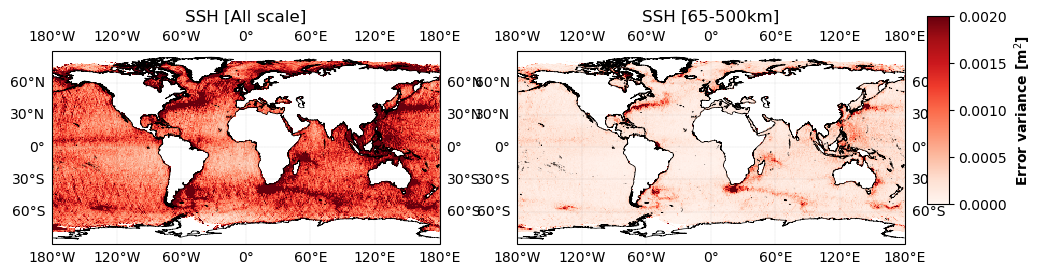

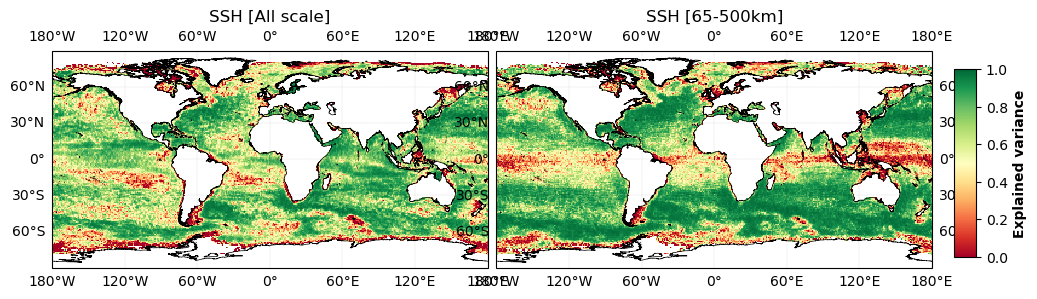

In [13]:
plot_stat_score_map_png(stat_output_filename)

In [14]:
# plot_stat_by_regimes(stat_output_filename)
plot_stat_by_regimes(stat_output_filename)[[
    'var_score_allscale', 'var_score_filtered',
    'rmse_score_allscale', 'rmse_score_filtered',
]]

,var_score_allscale,var_score_filtered,rmse_score_allscale,rmse_score_filtered
coastal,0.733369,0.743047,0.656829,0.493077
offshore_highvar,0.954921,0.966442,0.809794,0.816813
offshore_lowvar,0.830844,0.891290,0.740184,0.670288
equatorial_band,0.769093,0.480479,0.712993,0.279225
arctic,0.538675,0.538478,0.597003,0.320649
antarctic,0.293718,0.397523,0.417632,0.223242


### Métriques spectrales

In [15]:
compute_psd_scores_v2(
    ds_interp, psd_output_filename, lenght_scale=segment_length,
    method_name=method_name,
)

2026-06-25 01:19:10 INFO     Segment computation...
2026-06-25 01:19:14 INFO     Spectral analysis...
2026-06-25 01:22:51 INFO     Saving ouput...
2026-06-25 01:22:56 INFO     PSD file saved as: ./results/psd_sla_miost.nc


Averaged effective resolution: 205.42967762628822 km


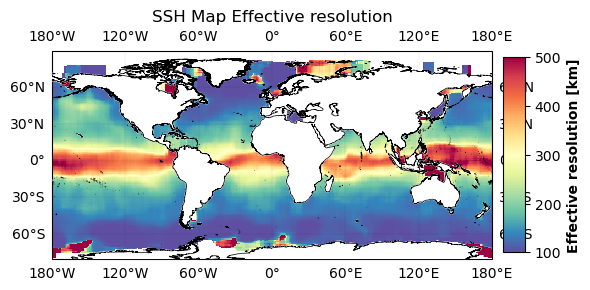

In [16]:
plot_effective_resolution_png(psd_output_filename)